In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import tensorflow as tf

# Load Fashion-MNIST
(X_train, y_train), (X_test, y_test) = (
tf.keras.datasets.fashion_mnist.load_data()
)

# Normalize pixel values to [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Flatten 28 x 28 images into 784 features
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
print("Training:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

Training: (48000, 784) Validation: (12000, 784) Test: (10000, 784)


In [16]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(784,)),              #  pixel inputs
    tf.keras.layers.Dense(32, activation="relu"),    # hidden neurons
    tf.keras.layers.Dense(10, activation="softmax")  # 10 digit probabilities
])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)



In [18]:
history = model.fit(
    X_train, y_train,
      epochs=50, batch_size=32, verbose=1
)
print("Final training accuracy:",
       round(history.history["accuracy"][-1], 3))

Epoch 1/50


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8043 - loss: 0.5649
Epoch 2/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8513 - loss: 0.4197
Epoch 3/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8621 - loss: 0.3860
Epoch 4/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8695 - loss: 0.3646
Epoch 5/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8754 - loss: 0.3487
Epoch 6/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8793 - loss: 0.3361
Epoch 7/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8832 - loss: 0.3251
Epoch 8/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8860 - loss: 0.3161
Epoch 9/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8889 - loss: 0.3072
Epoch 10/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8918 - loss: 0.2995
Epoch 11/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8932 - loss: 0.2927
Epoch 12/50
1500/1500 ━━━━━━━━━━━━━━━━━━━

In [19]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
probabilities = model.predict(X_test, verbose=0)
predicted_digits = np.argmax(probabilities, axis=1)

print("Test accuracy:", round(accuracy, 3))
print("Actual digit:", y_test[0])
print("Predicted digit:", predicted_digits[0])
print("10 probabilities:", probabilities[0].round(3))

Test accuracy: 0.861
Actual digit: 9
Predicted digit: 9
10 probabilities: [0.    0.    0.    0.    0.    0.    0.    0.012 0.    0.988]


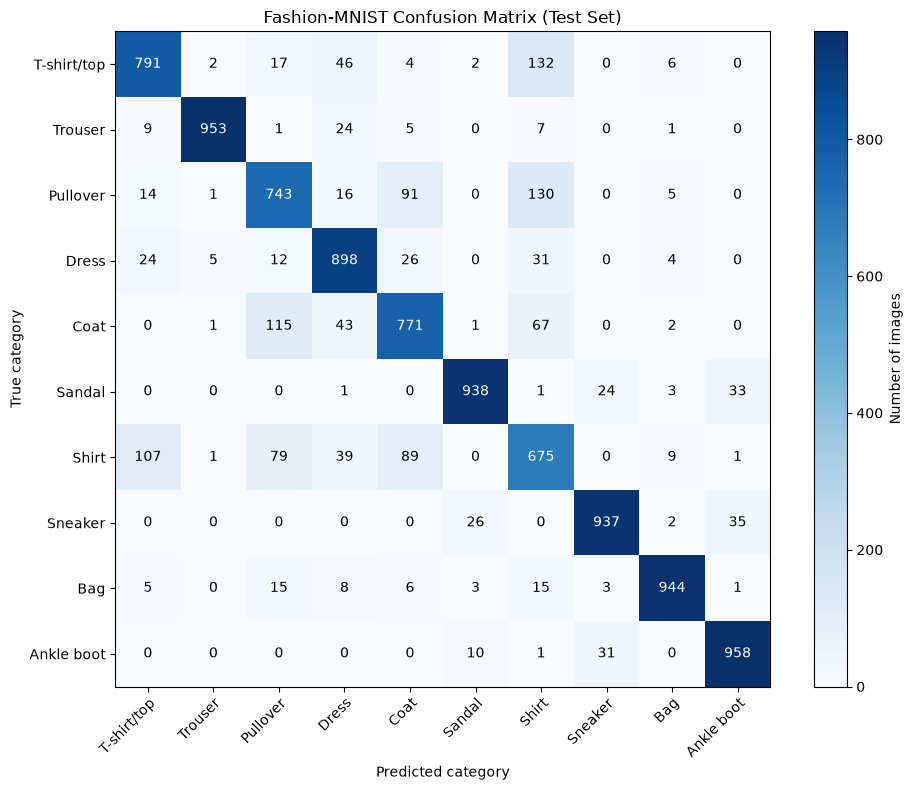

Most common confusion: T-shirt/top mistaken for Shirt (132 test images).
The diagonal shows correct predictions, while off-diagonal cells show which categories are mistaken for one another. Overall accuracy gives only the fraction correct and does not reveal these category-specific errors.


In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(class_names)))

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(cm, cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of images")
ax.set(
    xticks=np.arange(len(class_names)),
    yticks=np.arange(len(class_names)),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted category",
    ylabel="True category",
    title="Fashion-MNIST Confusion Matrix (Test Set)"
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
threshold = cm.max() / 2
for row in range(cm.shape[0]):
    for col in range(cm.shape[1]):
        ax.text(col, row, str(cm[row, col]), ha="center", va="center",
                color="white" if cm[row, col] > threshold else "black")
fig.tight_layout()
plt.show()

misclassifications = cm.copy()
np.fill_diagonal(misclassifications, 0)
true_class, predicted_class = np.unravel_index(
    np.argmax(misclassifications), misclassifications.shape
)
print(
    f"Most common confusion: {class_names[true_class]} mistaken for "
    f"{class_names[predicted_class]} ({cm[true_class, predicted_class]} test images)."
)
print(
    "The diagonal shows correct predictions, while off-diagonal cells show "
    "which categories are mistaken for one another. Overall accuracy gives "
    f"an overview of the model's performance."
)
